# Smart City Digital Twin — Business Report
### A Business-focused view of city health, mobility, resilience, and safety

<a id="toc"></a>
## Table of Contents

- [Executive Summary](#summary)
- [1. City Health and Environment](#health)
- [2. Mobility and Public Services](#mobility)
- [3. Energy and Infrastructure Resilience](#energy)
- [4. Emergency Response and Safety](#safety)
- [5. City-wide Risk and System Reliability](#risk)
- [6. Management KPI Summary](#kpis)
- [7. Suitable Machine-Learning Problems](#ml)
- [Final Recommendations](#recommendations)

## Purpose
This report turns the sensor and event data into practical priorities for city managers. It focuses on where performance is weak, why it is weak, and which KPIs should be monitored.

**Data scope:** 20 districts; hourly operational data from weather, traffic, public transport, power, and air-quality systems; plus city-event and emergency-event logs.

## Questions answered
1. Which districts are performing well or poorly?  
2. What are the biggest operational risks?  
3. Which systems are most vulnerable?  
4. Are weather and public events affecting performance?  
5. Where are possible sensor or hardware failures?  
6. Which KPIs should managers monitor?  
7. Which future ML problems are suitable?

## Loading the analysed data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('darkgrid')

In [2]:
districts = pd.read_csv('districts.csv')
weather = pd.read_csv('weather.csv')
traffic = pd.read_csv('traffic.csv')
transport = pd.read_csv('public_transport.csv')
power = pd.read_csv('power_grid.csv')
air = pd.read_csv('air_quality.csv')
events = pd.read_csv('city_events.csv')
emergency = pd.read_csv('emergency_events.csv')

for table in [weather, traffic, transport, power, air, emergency]:
    table['timestamp'] = pd.to_datetime(table['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

events['start_timestamp'] = pd.to_datetime(events['start_timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
events['end_timestamp'] = pd.to_datetime(events['end_timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

# Remove duplicated hourly readings before merging.
traffic = traffic.drop_duplicates(['district_id', 'timestamp'])
air = air.drop_duplicates(['district_id', 'timestamp'])

<a id="summary"></a>
# Executive Summary

1. **Industrial Zone is the main environmental hotspot:** it has the highest average AQI and pollution-alert rate.
2. **Old Town is the clearest mobility and safety pressure point:** it has the city’s highest congestion, lowest average traffic speed, and slowest emergency response.
3. **North Residential has the greatest public-transport load:** it has the highest ridership and operates at full or above-planned occupancy.
4. **Grid resilience needs attention in Central Park, Old Town, and West Residential:** they have the highest grid-stress rates; Central Park also has one of the highest outage rates.
5. **Weather and major events materially affect operations:** storms and rain affect mobility and outages, while high-impact events increase traffic, transit demand, and electricity demand.
6. **Sensor gaps are systematic, not random:** readings are missing when systems report Communication-Loss, Storm-Affected, or Outage-Affected status.
7. **Best future ML opportunities:** predict congestion, air-quality alerts, grid overload/outage risk, and emergency response time.

<a id="health"></a>
# 1. City Health and Environment

## Air quality by district
This KPI identifies where pollution exposure and alert risk are highest.

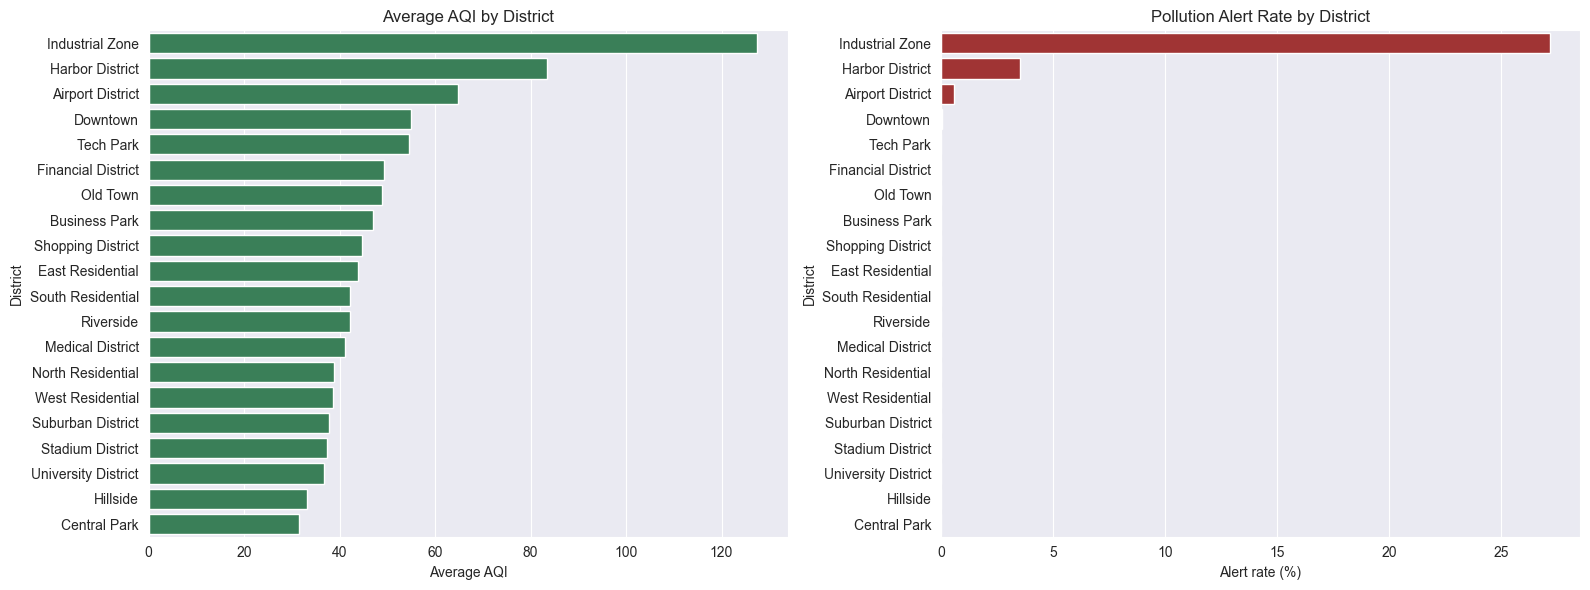

,district_name,average_aqi,pollution_alert_rate
8,Industrial Zone,127.447359,27.178376
6,Harbor District,83.360926,3.512774
0,Airport District,64.764001,0.558850
3,Downtown,54.888040,0.030414
17,Tech Park,54.632420,0.007603


In [3]:
air_district = air.merge(districts[['district_id', 'district_name']], on='district_id').groupby('district_name').agg(
    average_aqi=('synthetic_aqi', 'mean'),
    pollution_alert_rate=('pollution_alert_flag', lambda x: x.mean() * 100)
).reset_index().sort_values('average_aqi', ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(air_district, x='average_aqi', y='district_name', color='seagreen', ax=ax[0])
ax[0].set_title('Average AQI by District')
ax[0].set_xlabel('Average AQI')
ax[0].set_ylabel('District')

sns.barplot(air_district, x='pollution_alert_rate', y='district_name', color='firebrick', ax=ax[1])
ax[1].set_title('Pollution Alert Rate by District')
ax[1].set_xlabel('Alert rate (%)')
ax[1].set_ylabel('District')

plt.tight_layout()
plt.show()

air_district.head()

**Manager takeaway:** Industrial Zone should be the priority for air-quality action. High PM2.5, PM10, and NO₂ values move together with AQI, so they represent real pollution episodes rather than isolated sensor noise.

## Weather conditions and pollution
This shows whether pollution conditions differ during clear, rainy, storm, and heatwave periods.

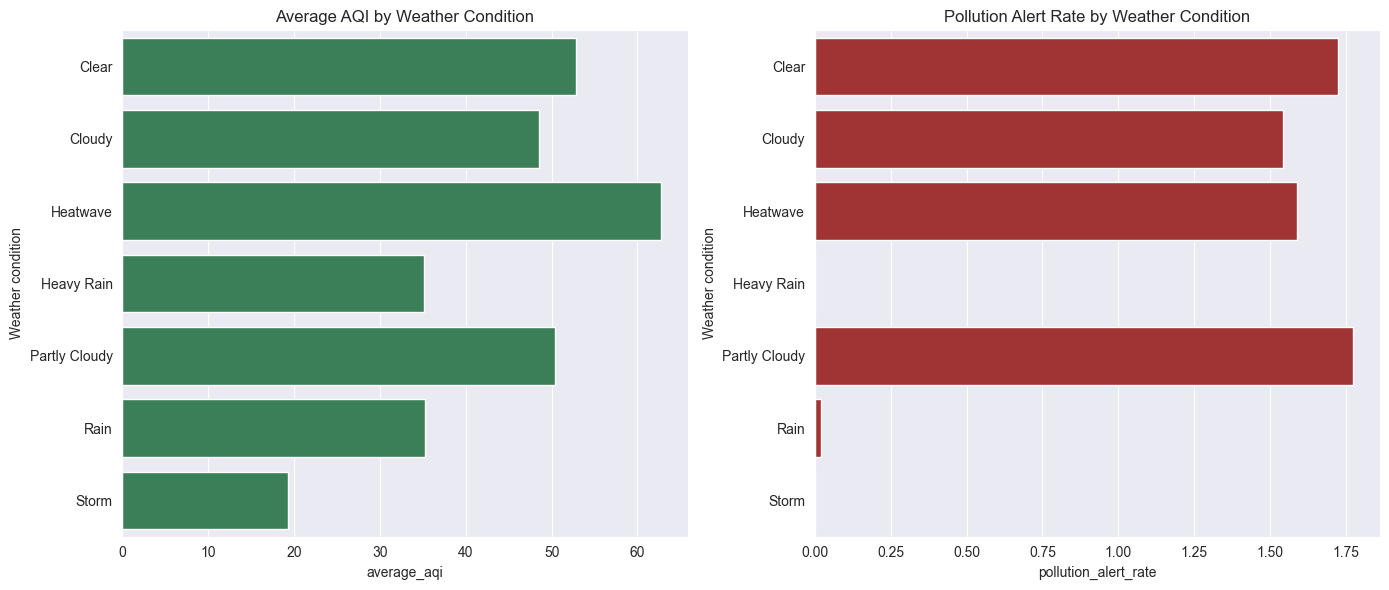

In [4]:
weather_air = weather.merge(air, on=['district_id', 'timestamp'], suffixes=('_weather', '_air'))
weather_air_kpi = weather_air.groupby('weather_condition').agg(
    average_aqi=('synthetic_aqi', 'mean'),
    pollution_alert_rate=('pollution_alert_flag', lambda x: x.mean() * 100)
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(weather_air_kpi, x='average_aqi', y='weather_condition', color='seagreen', ax=ax[0])
ax[0].set_title('Average AQI by Weather Condition')
ax[0].set_ylabel('Weather condition')

sns.barplot(weather_air_kpi, x='pollution_alert_rate', y='weather_condition', color='firebrick', ax=ax[1])
ax[1].set_title('Pollution Alert Rate by Weather Condition')
ax[1].set_ylabel('Weather condition')
    
plt.tight_layout()
plt.show()

<a id="mobility"></a>
# 2. Mobility and Public Services

## Rush-hour traffic performance
Rush hours are the city’s largest recurring mobility pressure.

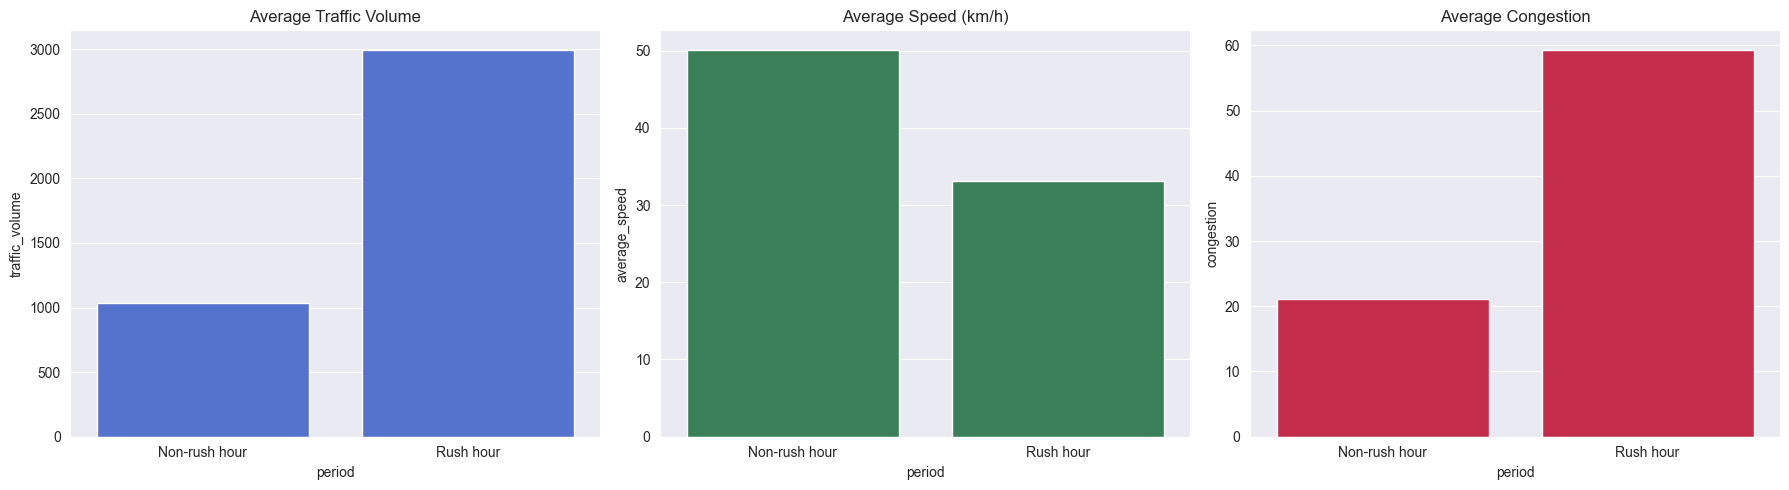

,rush_hour_flag,traffic_volume,average_speed,congestion,period
0,0.0,1034.732669,50.102614,21.127628,Non-rush hour
1,1.0,2996.007572,33.100668,59.323383,Rush hour


In [5]:
rush_hour = traffic.groupby('rush_hour_flag').agg(
    traffic_volume=('traffic_volume', 'mean'),
    average_speed=('average_speed_kmh', 'mean'),
    congestion=('congestion_index', 'mean')
).reset_index()
rush_hour['period'] = rush_hour['rush_hour_flag'].map({0: 'Non-rush hour', 1: 'Rush hour'})

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(rush_hour, x='period', y='traffic_volume', color='royalblue', ax=ax[0])
ax[0].set_title('Average Traffic Volume')
sns.barplot(rush_hour, x='period', y='average_speed', color='seagreen', ax=ax[1])
ax[1].set_title('Average Speed (km/h)')
sns.barplot(rush_hour, x='period', y='congestion', color='crimson', ax=ax[2])
ax[2].set_title('Average Congestion')
plt.tight_layout()
plt.show()
rush_hour

**Manager takeaway:** Rush hour nearly triples traffic volume, reduces speed, and raises congestion sharply. Old Town should be the first location for traffic-flow interventions.

## Transit demand, crowding, and delay
Occupancy above 100% is treated as overcrowding, not an invalid value. The metric is capped at 150% in this dataset.

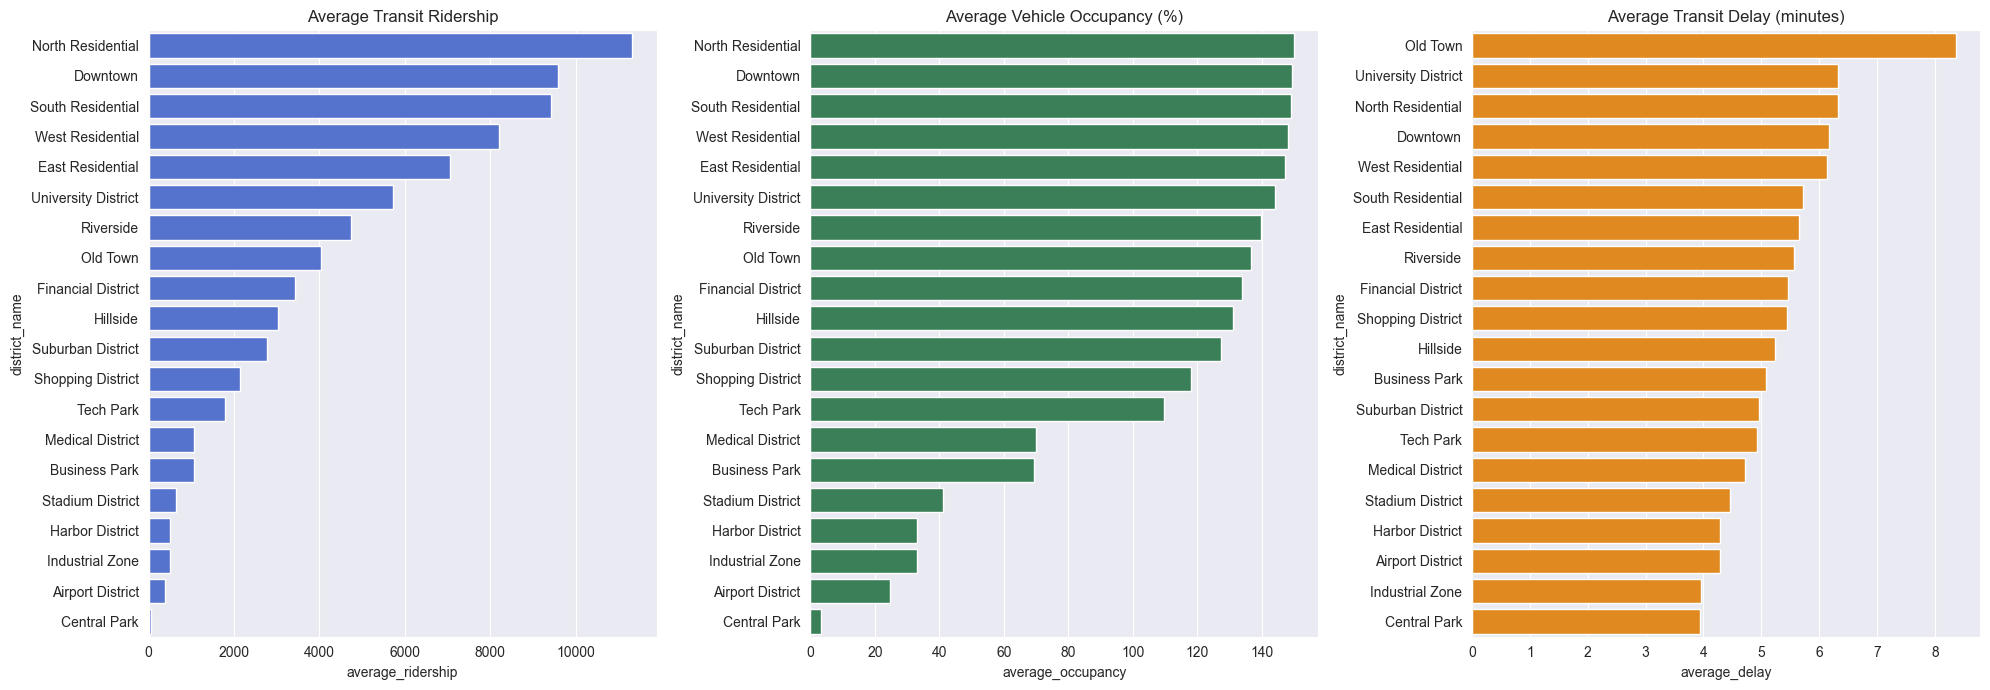

In [6]:
transit_district = transport.merge(districts[['district_id', 'district_name']], on='district_id').groupby('district_name').agg(
    average_ridership=('passenger_count', 'mean'),
    average_occupancy=('vehicle_occupancy_percent', 'mean'),
    average_delay=('average_delay_minutes', 'mean')
).reset_index()

fig, ax = plt.subplots(1, 3, figsize=(20, 7))
sns.barplot(transit_district.sort_values('average_ridership', ascending=False), x='average_ridership', y='district_name', color='royalblue', ax=ax[0])
ax[0].set_title('Average Transit Ridership')
sns.barplot(transit_district.sort_values('average_occupancy', ascending=False), x='average_occupancy', y='district_name', color='seagreen', ax=ax[1])
ax[1].set_title('Average Vehicle Occupancy (%)')
sns.barplot(transit_district.sort_values('average_delay', ascending=False), x='average_delay', y='district_name', color='darkorange', ax=ax[2])
ax[2].set_title('Average Transit Delay (minutes)')
plt.tight_layout()
plt.show()

**Manager takeaway:** North Residential needs capacity planning because it has the highest ridership and full/overcrowded vehicles. Old Town needs reliability work because it has the longest average delays.

## Do public events affect mobility?
For each event, the chart compares congestion during its operating hours with the typical congestion in the same district and hour of day.

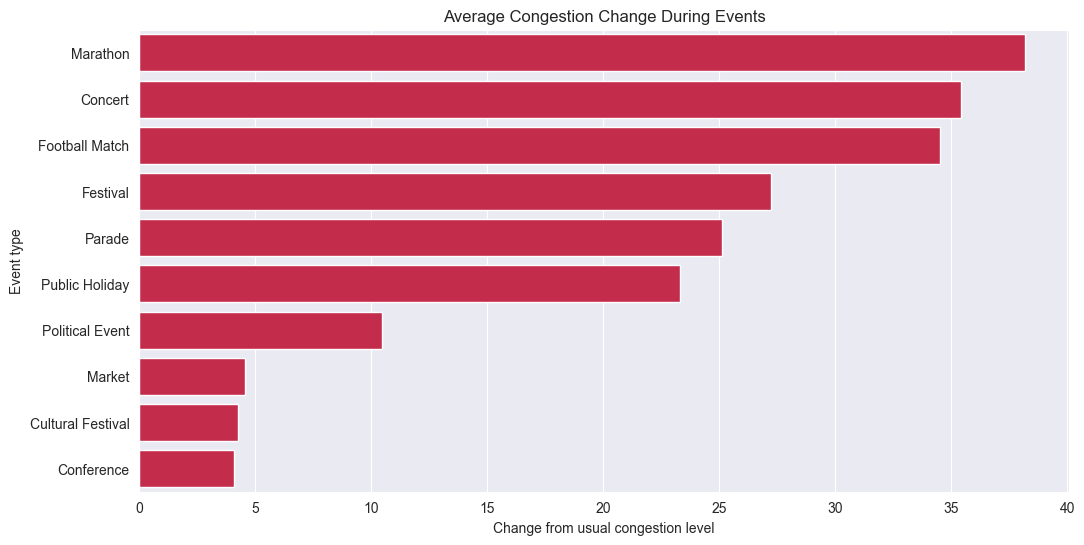

In [7]:
traffic['hour'] = traffic['timestamp'].dt.hour
usual_congestion = traffic.groupby(['district_id', 'hour']).agg(
    usual_congestion=('congestion_index', 'mean')
).reset_index()

event_traffic = events.merge(traffic[['district_id', 'timestamp', 'congestion_index']], on='district_id')
event_traffic = event_traffic[
    (event_traffic['timestamp'] >= event_traffic['start_timestamp']) &
    (event_traffic['timestamp'] <= event_traffic['end_timestamp'])
]
event_traffic['hour'] = event_traffic['timestamp'].dt.hour

event_impact = event_traffic.merge(usual_congestion, on=['district_id', 'hour']).groupby('event_type').agg(
    congestion_uplift=('congestion_index', 'mean'),
    usual_congestion=('usual_congestion', 'mean')
).reset_index()
event_impact['congestion_uplift'] = event_impact['congestion_uplift'] - event_impact['usual_congestion']

sns.barplot(event_impact.sort_values('congestion_uplift', ascending=False), x='congestion_uplift', y='event_type', color='crimson')
plt.title('Average Congestion Change During Events')
plt.xlabel('Change from usual congestion level')
plt.ylabel('Event type')
plt.show()

**Manager takeaway:** Large events such as marathons, football matches, and concerts create the strongest congestion increase. Their traffic plans should include extra transit capacity and road-management support.

<a id="energy"></a>
# 3. Energy and Infrastructure Resilience

## Electricity demand, grid stress, and outages

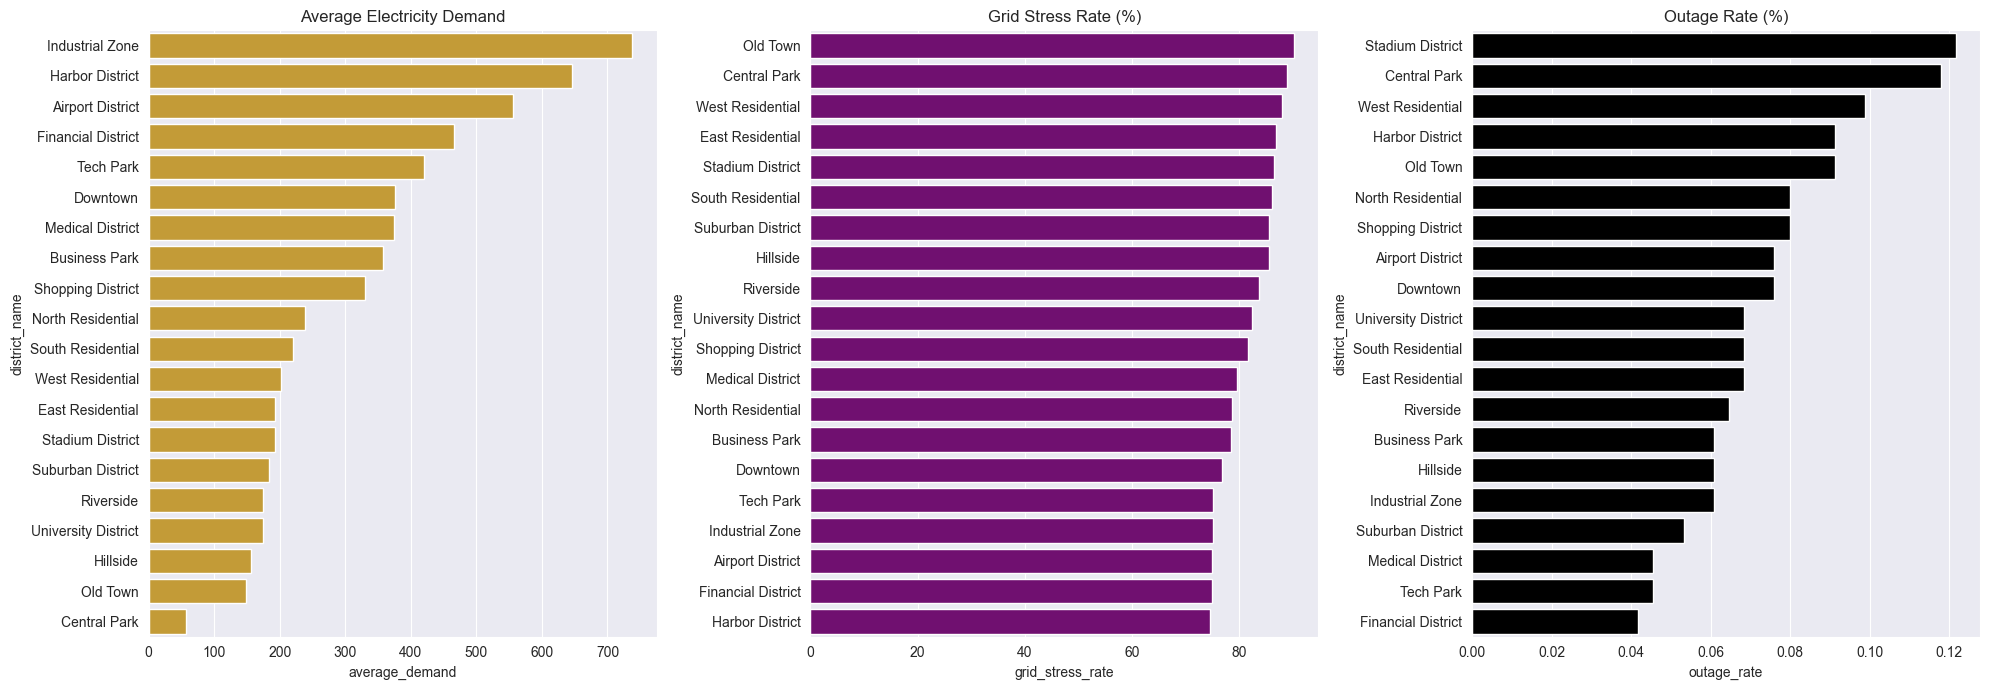

In [8]:
power_district = power.merge(districts[['district_id', 'district_name']], on='district_id').groupby('district_name').agg(
    average_demand=('electricity_demand_mwh', 'mean'),
    grid_stress_rate=('grid_stress_index', lambda x: (x > 0).mean() * 100),
    outage_rate=('outage_flag', lambda x: x.mean() * 100)
).reset_index()

fig, ax = plt.subplots(1, 3, figsize=(20, 7))
sns.barplot(power_district.sort_values('average_demand', ascending=False), x='average_demand', y='district_name', color='goldenrod', ax=ax[0])
ax[0].set_title('Average Electricity Demand')
sns.barplot(power_district.sort_values('grid_stress_rate', ascending=False), x='grid_stress_rate', y='district_name', color='purple', ax=ax[1])
ax[1].set_title('Grid Stress Rate (%)')
sns.barplot(power_district.sort_values('outage_rate', ascending=False), x='outage_rate', y='district_name', color='black', ax=ax[2])
ax[2].set_title('Outage Rate (%)')
plt.tight_layout()
plt.show()

**Manager takeaway:** Industrial Zone has the highest demand. Central Park, Old Town, and West Residential have the highest grid stress. There are 3,144 demand-over-capacity observations, so overload prevention should be a management priority.

## Does weather affect electricity demand and outages?

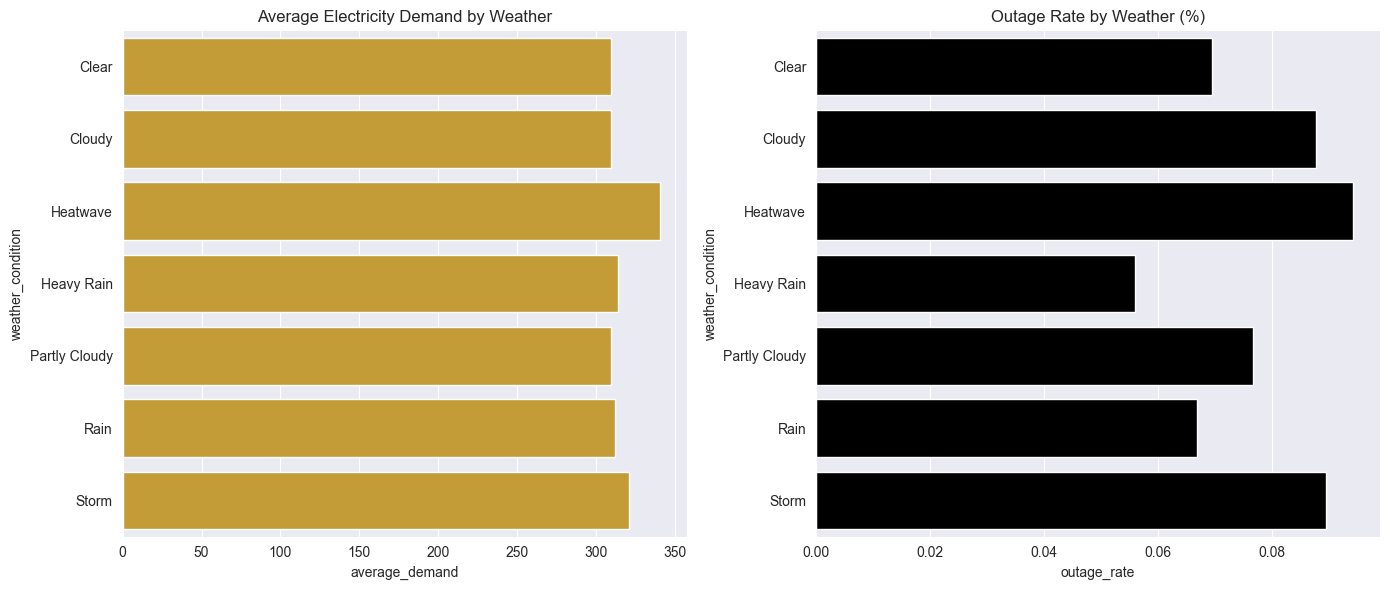

In [9]:
weather_power = weather.merge(power, on=['district_id', 'timestamp'], suffixes=('_weather', '_power'))
weather_power_kpi = weather_power.groupby('weather_condition').agg(
    average_demand=('electricity_demand_mwh', 'mean'),
    outage_rate=('outage_flag', lambda x: x.mean() * 100)
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(weather_power_kpi, x='average_demand', y='weather_condition', color='goldenrod', ax=ax[0])
ax[0].set_title('Average Electricity Demand by Weather')
sns.barplot(weather_power_kpi, x='outage_rate', y='weather_condition', color='black', ax=ax[1])
ax[1].set_title('Outage Rate by Weather (%)')
plt.tight_layout()
plt.show()

<a id="safety"></a>
# 4. Emergency Response and Safety

## Response time is prioritized by severity
A good emergency system should respond faster to more severe incidents.

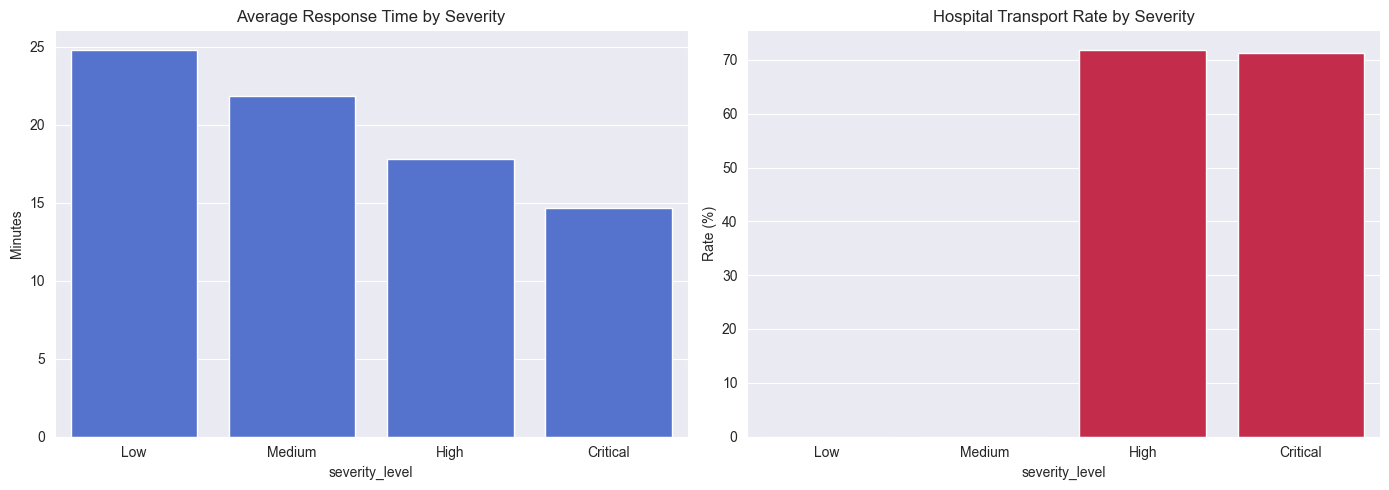

,severity_level,average_response_time,hospital_transport_rate
0,Critical,14.648868,71.340524
1,High,17.806402,71.889169
2,Low,24.816958,0.000000
3,Medium,21.858099,0.000000


In [10]:
response_by_severity = emergency.groupby('severity_level').agg(
    average_response_time=('response_time_minutes', 'mean'),
    hospital_transport_rate=('hospital_transport_required', lambda x: x.mean() * 100)
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(response_by_severity, x='severity_level', y='average_response_time', color='royalblue', ax=ax[0], order=['Low', 'Medium', 'High', 'Critical'])
ax[0].set_title('Average Response Time by Severity')
ax[0].set_ylabel('Minutes')
sns.barplot(response_by_severity, x='severity_level', y='hospital_transport_rate', color='crimson', ax=ax[1], order=['Low', 'Medium', 'High', 'Critical'])
ax[1].set_title('Hospital Transport Rate by Severity')
ax[1].set_ylabel('Rate (%)')
plt.tight_layout()
plt.show()
response_by_severity

**Manager takeaway:** Critical emergencies receive the fastest response, showing that dispatch is prioritizing severity correctly. Medical Emergencies and Traffic Accidents are the main demand categories and should drive staffing plans.

## Traffic congestion and emergency response

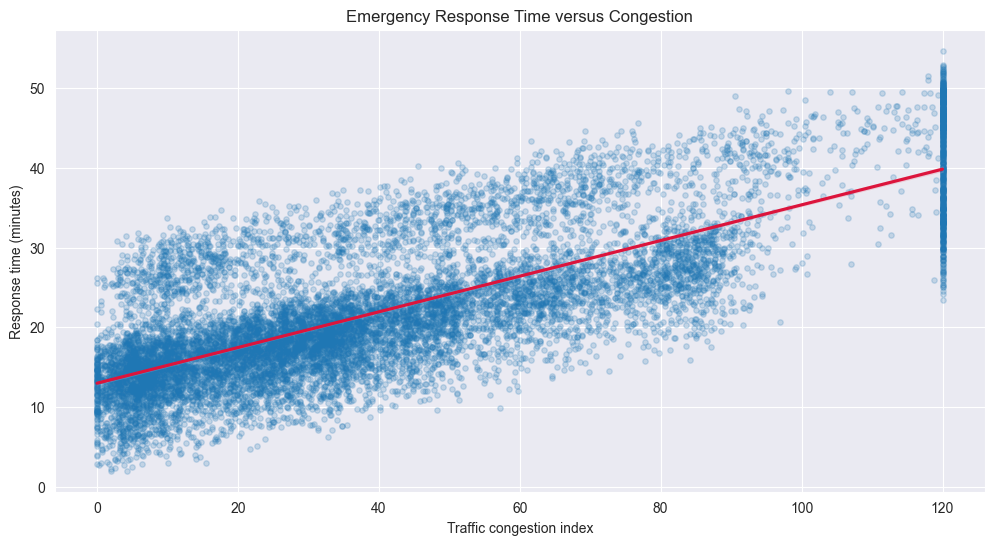

np.float64(0.7627332634308394)

In [11]:
emergency_hour = emergency.copy()
emergency_hour['timestamp'] = emergency_hour['timestamp'].dt.floor('h')
emergency_traffic = emergency_hour.merge(traffic, on=['district_id', 'timestamp'], how='left')

sns.regplot(
    emergency_traffic.dropna(subset=['congestion_index']),
    x='congestion_index', y='response_time_minutes',
    scatter_kws={'alpha': 0.2, 's': 15}, line_kws={'color': 'crimson'}
)
plt.title('Emergency Response Time versus Congestion')
plt.xlabel('Traffic congestion index')
plt.ylabel('Response time (minutes)')
plt.show()

emergency_traffic[['congestion_index', 'response_time_minutes']].corr().iloc[0, 1]

<a id="risk"></a>
# 5. City wide Risk and System Reliability

## District operational risk profile
This is a comparison tool, not a formal score. Darker cells mean relatively higher operational pressure within that indicator.

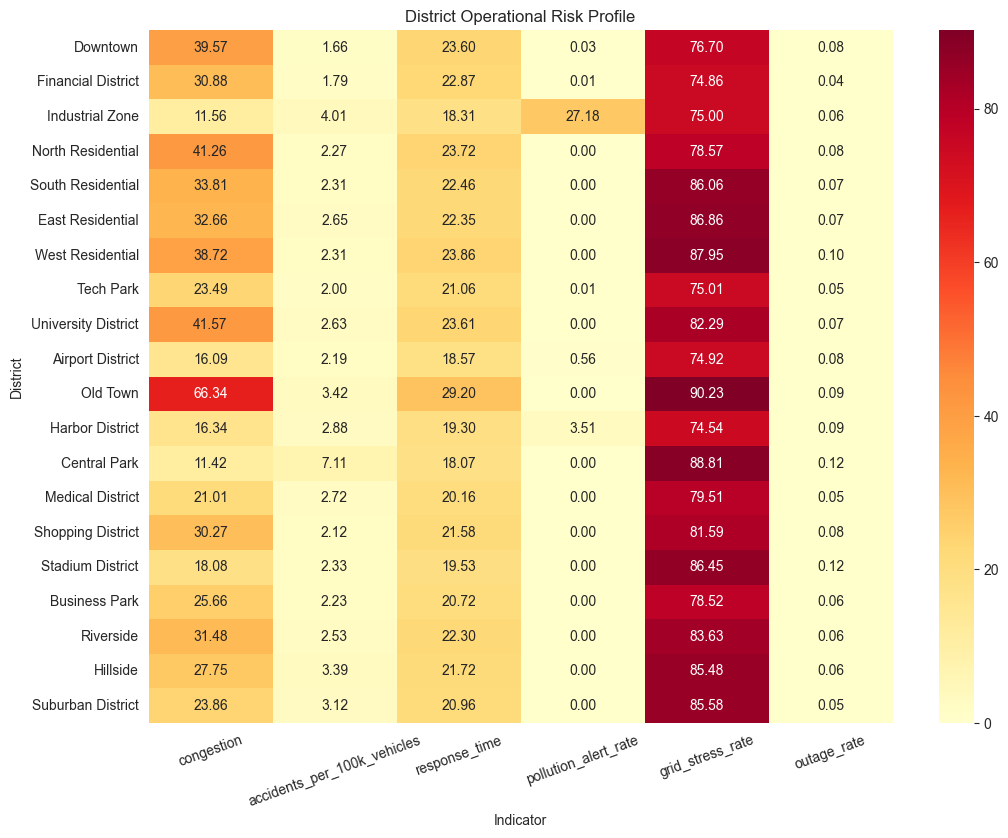

In [12]:
traffic_profile = traffic.groupby('district_id').agg(
    congestion=('congestion_index', 'mean'),
    accidents=('accident_count', 'sum'),
    traffic_volume=('traffic_volume', 'sum')
).reset_index()
traffic_profile['accidents_per_100k_vehicles'] = traffic_profile['accidents'] / traffic_profile['traffic_volume'] * 100000

emergency_profile = emergency.groupby('district_id').agg(
    emergency_count=('event_id', 'count'),
    response_time=('response_time_minutes', 'mean')
).reset_index()

air_profile = air.groupby('district_id').agg(
    pollution_alert_rate=('pollution_alert_flag', lambda x: x.mean() * 100)
).reset_index()

power_profile = power.groupby('district_id').agg(
    grid_stress_rate=('grid_stress_index', lambda x: (x > 0).mean() * 100),
    outage_rate=('outage_flag', lambda x: x.mean() * 100)
).reset_index()

risk_profile = districts.merge(traffic_profile, on='district_id').merge(emergency_profile, on='district_id').merge(air_profile, on='district_id').merge(power_profile, on='district_id')
risk_columns = ['congestion', 'accidents_per_100k_vehicles', 'response_time', 'pollution_alert_rate', 'grid_stress_rate', 'outage_rate']

plt.figure(figsize=(12, 9))
sns.heatmap(risk_profile.set_index('district_name')[risk_columns], cmap='YlOrRd', annot=True, fmt='.2f')
plt.title('District Operational Risk Profile')
plt.xlabel('Indicator')
plt.ylabel('District')
plt.xticks(rotation=20)
plt.show()

**Manager takeaway:** The high-priority districts are not identical across systems: Industrial Zone is the environmental priority; Old Town is the mobility/safety priority; Central Park and West Residential require grid-resilience attention; North Residential needs transit capacity planning.

## Possible sensor or hardware failures
Non-normal sensor status is used as the failure indicator. Missing readings occur in these abnormal-status rows, so values should be treated as unavailable rather than as zero.

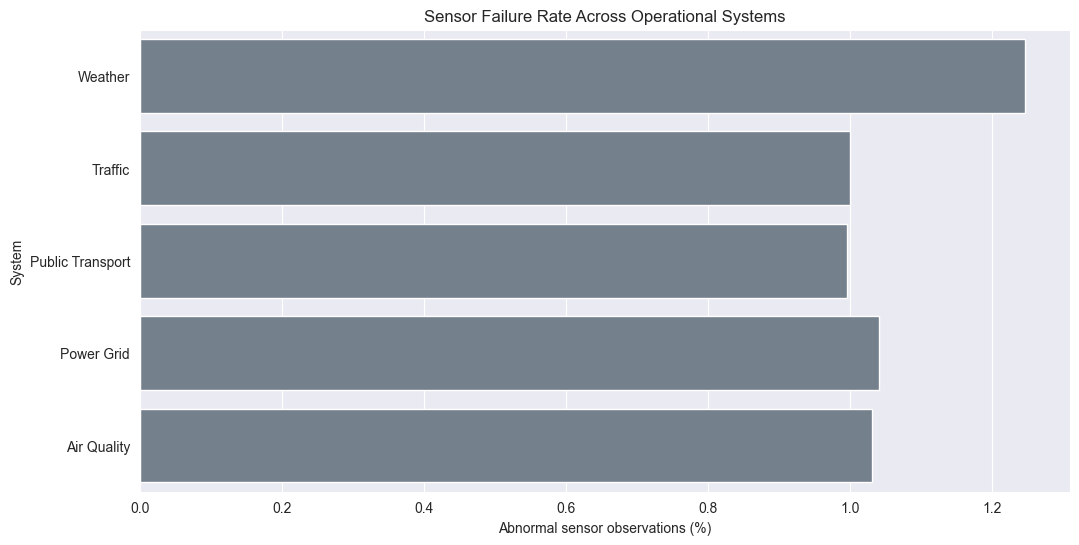

,System,Abnormal sensor rate (%)
0,Weather,1.247149
1,Traffic,0.999468
2,Public Transport,0.996426
3,Power Grid,1.040906
4,Air Quality,1.031212


In [13]:
sensor_failures = pd.DataFrame({
    'System': ['Weather', 'Traffic', 'Public Transport', 'Power Grid', 'Air Quality'],
    'Abnormal sensor rate (%)': [
        (weather['sensor_status'] != 'Normal').mean() * 100,
        (traffic['sensor_status'] != 'Normal').mean() * 100,
        (transport['sensor_status'] != 'Normal').mean() * 100,
        (power['sensor_status'] != 'Normal').mean() * 100,
        (air['sensor_status'] != 'Normal').mean() * 100
    ]
})

sns.barplot(sensor_failures, x='Abnormal sensor rate (%)', y='System', color='slategray')
plt.title('Sensor Failure Rate Across Operational Systems')
plt.xlabel('Abnormal sensor observations (%)')
plt.ylabel('System')
plt.show()
sensor_failures

<a id="kpis"></a>
# 6. Management KPI Summary

City managers should monitor these KPIs regularly:

1. **Average AQI and pollution-alert rate** — especially Industrial Zone.  
2. **Rush-hour congestion and average speed** — especially Old Town.  
3. **Transit ridership, occupancy, delay, and disruption rate** — especially North Residential and Old Town.  
4. **Demand-over-capacity count, grid-stress rate, and outage rate** — especially Central Park, Old Town, and West Residential.  
5. **Emergency response time by severity and district** — especially Old Town.  
6. **Non-normal sensor rate by system** — to identify data and hardware reliability issues.  
7. **Event-period congestion uplift** — for planning major events.

<a id="ml"></a>
# 7. Suitable Machine-Learning Problems

| Business problem | Suggested target | Useful inputs | Value to the city |
|---|---|---|---|
| Congestion prediction | `congestion_index` or high-congestion flag | hour, weekend, weather, events, incidents, district | Prepare traffic control before rush periods |
| Pollution-alert prediction | `pollution_alert_flag` | weather, district type, past pollutant readings | Issue targeted public-health alerts |
| Grid overload/outage prediction | overload flag or `outage_flag` | demand, renewable output, weather, historical load | Prevent failures and improve maintenance planning |
| Emergency response-time prediction | `response_time_minutes` | severity, emergency type, district, traffic, weather | Improve dispatch allocation and response targets |
| Transit demand prediction | `passenger_count` | hour, weather, events, district | Schedule vehicles before overcrowding occurs |

<a id="recommendations"></a>
# Final Recommendations

1. Prioritize emissions and exposure reduction in Industrial Zone.
2. Reduce Old Town congestion through peak-hour traffic controls and emergency-route protection.
3. Add or rebalance transit capacity toward North Residential and investigate persistent delays in Old Town.
4. Strengthen monitoring and preventive maintenance in high-stress grid districts.
5. Require operational plans for large events, including transit, traffic, and power readiness.
6. Track abnormal sensor statuses as a formal reliability KPI and exclude failed readings from operational decisions.
7. Start with forecasting pilots for congestion, pollution alerts, and grid overload because these have clear operational actions.